<a href="https://colab.research.google.com/github/bibanaksu/PM25-Forecasting-GRU/blob/main/01_data_exploration.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [13]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv('/content/combined_gee_pm25.csv')


print("Dataset shape:", df.shape)
print("\nFirst 5 rows:")
display(df.head())



Dataset shape: (41718, 15)

First 5 rows:


,date,datetime_utc,id,latitude,longitude,temperature_celsius,pressure_mb,wind_u,wind_v,NO2,CO,O3,AOD,pm25,sensor_name
0,2016-11-25,2016-11-25 00:00:00,1,38.788056,-0.697222,6.493180,946.288660,0.230240,0.735303,NaN,NaN,NaN,0.1110,2.750000,ONTINYENT
1,2016-11-25,2016-11-25 00:00:00,36,39.945278,-0.056389,9.251236,993.626994,0.783218,-0.592618,NaN,NaN,NaN,0.0220,11.666667,ALMASSORA-C. P. OCHANDO
2,2016-11-30,2016-11-30 00:00:00,35,40.051944,-0.189722,10.044782,981.911432,-2.211047,-1.568971,NaN,NaN,NaN,0.2380,2.400000,ALCORA
3,2016-11-30,2016-11-30 00:00:00,37,40.062222,0.072778,12.299584,1008.794766,-3.236886,-2.804465,NaN,NaN,NaN,0.2480,2.600000,BENICASSIM
4,2016-12-02,2016-12-02 00:00:00,1,38.788056,-0.697222,9.350630,953.114180,0.953454,0.293060,NaN,NaN,NaN,0.0755,2.750000,ONTINYENT


In [14]:

print("DATASET DESCRIPTION")
print("-------------------")

print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nDate range:")
print("Start:", df["date"].min())
print("End:", df["date"].max())

print("\nNumber of stations:", df["id"].nunique())

print("\nGeographical coverage:")
print("Latitude:", df["latitude"].min(), "to",
      df["latitude"].max())
print("Longitude:", df["longitude"].min(), "to",
      df["longitude"].max())


DATASET DESCRIPTION
-------------------
Number of rows: 41718
Number of columns: 15

Column names:
['date', 'datetime_utc', 'id', 'latitude', 'longitude', 'temperature_celsius', 'pressure_mb', 'wind_u', 'wind_v', 'NO2', 'CO', 'O3', 'AOD', 'pm25', 'sensor_name']

Data types:
date                    object
datetime_utc            object
id                       int64
latitude               float64
longitude              float64
temperature_celsius    float64
pressure_mb            float64
wind_u                 float64
wind_v                 float64
NO2                    float64
CO                     float64
O3                     float64
AOD                    float64
pm25                   float64
sensor_name             object
dtype: object

Date range:
Start: 2016-11-25
End: 2026-04-06

Number of stations: 98

Geographical coverage:
Latitude: 36.13331699932336 to 43.5302972250095
Longitude: -5.663499999930786 to 9.136389000276088


In [15]:

# Check missing values in each column

missing_values = df.isnull().sum()

print("MISSING VALUES PER COLUMN")
print("-------------------------")
print(missing_values)

print("\nTotal missing cells:",
      missing_values.sum())

print("Rows containing at least one missing value:",
      df.isnull().any(axis=1).sum())


MISSING VALUES PER COLUMN
-------------------------
date                      0
datetime_utc              0
id                        0
latitude                  0
longitude                 0
temperature_celsius       0
pressure_mb               0
wind_u                    0
wind_v                    0
NO2                    2410
CO                     2410
O3                     2451
AOD                       0
pm25                      0
sensor_name               0
dtype: int64

Total missing cells: 7271
Rows containing at least one missing value: 2451


                     Missing_Count  Missing_Percentage
date                             0                0.00
datetime_utc                     0                0.00
id                               0                0.00
latitude                         0                0.00
longitude                        0                0.00
temperature_celsius              0                0.00
pressure_mb                      0                0.00
wind_u                           0                0.00
wind_v                           0                0.00
NO2                           2410                5.78
CO                            2410                5.78
O3                            2451                5.88
AOD                              0                0.00
pm25                             0                0.00
sensor_name                      0                0.00


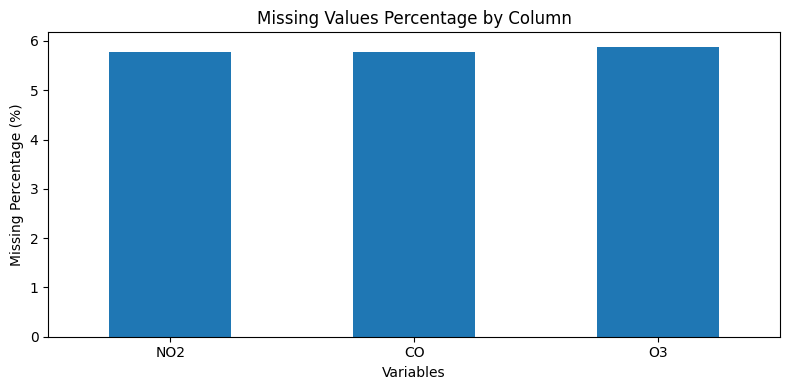

In [16]:

# Calculate missing value percentages

missing_report = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": (
        df.isnull().sum() / len(df) * 100
    ).round(2)
})

print(missing_report)

# Visualize missing values
missing_report[missing_report["Missing_Count"] > 0][
    "Missing_Percentage"
].plot(kind="bar", figsize=(8, 4))

plt.title("Missing Values Percentage by Column")
plt.ylabel("Missing Percentage (%)")
plt.xlabel("Variables")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


In [17]:

# Count complete duplicate rows

duplicate_count = df.duplicated().sum()

print("Complete duplicate records:",
      duplicate_count)


Complete duplicate records: 0


In [18]:

# Check repeated observations using key fields

key_columns = [
    "date",
    "latitude",
    "longitude",
    "id"
]

key_duplicates = df.duplicated(
    subset=key_columns
).sum()

print("Duplicate records based on key fields:",
      key_duplicates)


Duplicate records based on key fields: 0


In [19]:

timestamp_duplicates = df.duplicated(
    subset=["datetime_utc", "id"]
).sum()

print("Duplicate timestamps per station:",
      timestamp_duplicates)


Duplicate timestamps per station: 0


In [20]:

# Create a cleaning audit summary

audit_summary = pd.DataFrame({
    "Check": [
        "Total observations",
        "Total variables",
        "Total missing cells",
        "Rows with missing values",
        "Complete duplicate records",
        "Duplicate records based on key fields",
        "Duplicate timestamps per station"
    ],
    "Result": [
        len(df),
        len(df.columns),
        df.isnull().sum().sum(),
        df.isnull().any(axis=1).sum(),
        df.duplicated().sum(),
        df.duplicated(subset=[
            "date", "latitude", "longitude", "id"
        ]).sum(),
        df.duplicated(subset=[
            "datetime_utc", "id"
        ]).sum()
    ]
})

display(audit_summary)

audit_summary.to_csv(
    "Missing_Duplicates_Audit.csv",
    index=False
)

print("Audit report saved successfully!")


,Check,Result
0,Total observations,41718
1,Total variables,15
2,Total missing cells,7271
3,Rows with missing values,2451
4,Complete duplicate records,0
5,Duplicate records based on key fields,0
6,Duplicate timestamps per station,0


Audit report saved successfully!


In [21]:

# Convert date columns to datetime format

df["date"] = pd.to_datetime(
    df["date"],
    errors="coerce"
)

df["datetime_utc"] = pd.to_datetime(
    df["datetime_utc"],
    errors="coerce",
    utc=True
)

print("Date conversion completed!")

print("\nData types:")
print(df[["date", "datetime_utc"]].dtypes)


Date conversion completed!

Data types:
date                 datetime64[ns]
datetime_utc    datetime64[ns, UTC]
dtype: object


In [22]:

# Count invalid timestamps

invalid_dates = df["date"].isna().sum()

invalid_timestamps = df["datetime_utc"].isna().sum()

print("Invalid dates:", invalid_dates)
print("Invalid timestamps:", invalid_timestamps)


Invalid dates: 0
Invalid timestamps: 0


In [23]:

# Compare the two date columns

date_mismatch = (
    df["date"].dt.date !=
    df["datetime_utc"].dt.date
).sum()

print("Date mismatches:", date_mismatch)


Date mismatches: 0


In [24]:

# Check chronological ordering

is_sorted = df["datetime_utc"].is_monotonic_increasing

print("Dataset is chronologically sorted:", is_sorted)

print("\nFirst observation:")
print(df["datetime_utc"].min())

print("\nLast observation:")
print(df["datetime_utc"].max())


Dataset is chronologically sorted: True

First observation:
2016-11-25 00:00:00+00:00

Last observation:
2026-04-06 00:00:00+00:00


In [25]:

# Sort observations by station and date

df = df.sort_values(
    ["id", "datetime_utc"]
).copy()

# Calculate the number of days between consecutive observations
df["days_between_observations"] = (
    df.groupby("id")["datetime_utc"]
    .diff()
    .dt.days
)

# Examine the time gaps
print("Time gap distribution:")
print(
    df["days_between_observations"]
    .value_counts()
    .sort_index()
    .head(15)
)

# Count gaps larger than one day
large_gaps = (
    df["days_between_observations"] > 1
).sum()

print("\nGaps greater than one day:", large_gaps)



Time gap distribution:
days_between_observations
1.0     27943
2.0      6570
3.0      3032
4.0      1408
5.0       813
6.0       558
7.0       388
8.0       140
9.0        83
10.0       82
11.0       68
12.0       34
13.0       24
14.0       59
15.0       30
Name: count, dtype: int64

Gaps greater than one day: 13677


In [27]:

# Check station identifiers

print("Missing station IDs:",
      df["id"].isna().sum())

print("Number of unique station IDs:",
      df["id"].nunique())

print("\nObservations per station:")
print(df["id"].value_counts().describe())


Missing station IDs: 0
Number of unique station IDs: 98

Observations per station:
count      98.000000
mean      425.693878
std       277.894381
min         1.000000
25%       197.250000
50%       439.000000
75%       660.000000
max      1047.000000
Name: count, dtype: float64


In [28]:

# Check station ID and station name consistency

names_per_station = (
    df.groupby("id")["sensor_name"]
    .nunique()
)

print("Stations with multiple names:",
      (names_per_station > 1).sum())

print("\nNumber of unique station names:",
      df["sensor_name"].nunique())

# Check names associated with multiple IDs
ids_per_name = (
    df.groupby("sensor_name")["id"]
    .nunique()
)

print("\nNames associated with multiple IDs:")
print(ids_per_name[ids_per_name > 1])


Stations with multiple names: 0

Number of unique station names: 94

Names associated with multiple IDs:
sensor_name
LA ALJORRA          2
MOLINA DE SEGURA    2
MOMPEAN             2
SAN BASILIO         2
Name: id, dtype: int64


In [29]:

# Check missing coordinates

print("Missing latitude:",
      df["latitude"].isna().sum())

print("Missing longitude:",
      df["longitude"].isna().sum())

# Check invalid coordinate ranges

invalid_latitude = (
    (df["latitude"] < -90) |
    (df["latitude"] > 90)
).sum()

invalid_longitude = (
    (df["longitude"] < -180) |
    (df["longitude"] > 180)
).sum()

print("\nInvalid latitude:", invalid_latitude)
print("Invalid longitude:", invalid_longitude)


Missing latitude: 0
Missing longitude: 0

Invalid latitude: 0
Invalid longitude: 0


In [30]:

# Geographic coverage

print("Latitude range:")
print(df["latitude"].min(),
      "to", df["latitude"].max())

print("\nLongitude range:")
print(df["longitude"].min(),
      "to", df["longitude"].max())

print("\nUnique coordinate pairs:",
      df[["latitude", "longitude"]]
      .drop_duplicates().shape[0])


Latitude range:
36.13331699932336 to 43.5302972250095

Longitude range:
-5.663499999930786 to 9.136389000276088

Unique coordinate pairs: 98


In [31]:

# Check coordinate consistency by station ID

coordinates_per_station = (
    df.groupby("id")[["latitude", "longitude"]]
    .nunique()
)

inconsistent_stations = (
    (coordinates_per_station > 1)
    .any(axis=1)
)

print("Stations with changing coordinates:",
      inconsistent_stations.sum())


Stations with changing coordinates: 0


In [32]:

# Create metadata verification report

metadata_report = pd.DataFrame({
    "Check": [
        "Invalid dates",
        "Invalid timestamps",
        "Date mismatches",
        "Chronological ordering",
        "Unique station IDs",
        "Missing station IDs",
        "Unique station names",
        "Stations with multiple names",
        "Missing latitude",
        "Missing longitude",
        "Invalid latitude",
        "Invalid longitude",
        "Unique coordinate pairs",
        "Stations with changing coordinates",
        "Gaps greater than one day"
    ],

    "Result": [
        df["date"].isna().sum(),
        df["datetime_utc"].isna().sum(),
        (df["date"].dt.date !=
         df["datetime_utc"].dt.date).sum(),
        df["datetime_utc"].is_monotonic_increasing,
        df["id"].nunique(),
        df["id"].isna().sum(),
        df["sensor_name"].nunique(),
        (df.groupby("id")["sensor_name"]
         .nunique() > 1).sum(),
        df["latitude"].isna().sum(),
        df["longitude"].isna().sum(),
        ((df["latitude"] < -90) |
         (df["latitude"] > 90)).sum(),
        ((df["longitude"] < -180) |
         (df["longitude"] > 180)).sum(),
        df[["latitude", "longitude"]]
        .drop_duplicates().shape[0],
        inconsistent_stations.sum(),
        (df["days_between_observations"] > 1).sum()
    ]
})

display(metadata_report)

metadata_report.to_csv(
    "Metadata_Verification_Report.csv",
    index=False
)

print("Metadata report saved successfully!")


,Check,Result
0,Invalid dates,0
1,Invalid timestamps,0
2,Date mismatches,0
3,Chronological ordering,False
4,Unique station IDs,98
5,Missing station IDs,0
6,Unique station names,94
7,Stations with multiple names,0
8,Missing latitude,0
9,Missing longitude,0


Metadata report saved successfully!


In [33]:
# Keep an unchanged copy of the original dataset
df_raw = df.copy()

print("Original dataset shape:", df_raw.shape)

Original dataset shape: (41718, 16)


In [34]:
# Convert PM2.5 to numeric values
pm = pd.to_numeric(df_raw["pm25"], errors="coerce")

# Identify invalid values
missing_pm25 = pm.isna()
non_numeric_pm25 = df_raw["pm25"].notna() & pm.isna()
nonpositive_pm25 = pm <= 0
high_pm25 = pm >= 500

# Count each category
print("Missing PM2.5 values:", missing_pm25.sum())
print("Non-numeric PM2.5 values:", non_numeric_pm25.sum())
print("PM2.5 values <= 0:", nonpositive_pm25.sum())
print("PM2.5 values >= 500:", high_pm25.sum())

Missing PM2.5 values: 0
Non-numeric PM2.5 values: 0
PM2.5 values <= 0: 727
PM2.5 values >= 500: 8


In [35]:
# Combine all invalid-value conditions
invalid_mask = (
    missing_pm25 |
    non_numeric_pm25 |
    nonpositive_pm25 |
    high_pm25
)

# Keep only valid PM2.5 rows
df_clean = df_raw.loc[~invalid_mask].copy()

print("Rows before cleaning:", len(df_raw))
print("Rows removed:", invalid_mask.sum())
print("Rows after cleaning:", len(df_clean))

Rows before cleaning: 41718
Rows removed: 735
Rows after cleaning: 40983


In [36]:
print("Missing PM2.5 after cleaning:", df_clean["pm25"].isna().sum())
print("Minimum PM2.5:", df_clean["pm25"].min())
print("Maximum PM2.5:", df_clean["pm25"].max())

print("Values <= 0 remaining:", (df_clean["pm25"] <= 0).sum())
print("Values >= 500 remaining:", (df_clean["pm25"] >= 500).sum())

Missing PM2.5 after cleaning: 0
Minimum PM2.5: 0.0066666666666666
Maximum PM2.5: 484.9815
Values <= 0 remaining: 0
Values >= 500 remaining: 0


In [37]:
# Make sure PM2.5 is numeric
df_clean["pm25"] = pd.to_numeric(df_clean["pm25"])

# Export the cleaned dataset
df_clean.to_csv("PM25_Cleaned.csv", index=False)

print("Cleaned dataset exported successfully!")
print("File: PM25_Cleaned.csv")
print("Shape:", df_clean.shape)

Cleaned dataset exported successfully!
File: PM25_Cleaned.csv
Shape: (40983, 16)


In [42]:
# Calculate cleaning statistics
original_rows = len(df_raw)
removed_rows = len(df_raw) - len(df_clean)
remaining_rows = len(df_clean)
retained_percentage = (remaining_rows / original_rows) * 100

# Create a cleaning report
cleaning_report = pd.DataFrame({
    "Cleaning Operation": [
        "Original dataset",
        "Missing PM2.5 values",
        "Non-numeric PM2.5 values",
        "PM2.5 values <= 0",
        "PM2.5 values >= 500",
        "Total rows removed",
        "Final cleaned dataset",
        "Rows retained (%)"
    ],
    "Result": [
        original_rows,
        int(missing_pm25.sum()),
        int(non_numeric_pm25.sum()),
        int(nonpositive_pm25.sum()),
        int(high_pm25.sum()),
        removed_rows,
        remaining_rows,
        round(retained_percentage, 2)
    ]
})

# Export the report
cleaning_report.to_csv("Cleaning_Report.csv", index=False)

print(cleaning_report)
print("\nCleaning report exported successfully!")

         Cleaning Operation    Result
0          Original dataset  41718.00
1      Missing PM2.5 values      0.00
2  Non-numeric PM2.5 values      0.00
3         PM2.5 values <= 0    727.00
4       PM2.5 values >= 500      8.00
5        Total rows removed    735.00
6     Final cleaned dataset  40983.00
7         Rows retained (%)     98.24

Cleaning report exported successfully!
